<a href="https://colab.research.google.com/github/khanrumnaz19-glitch/beach-drowning-detection/blob/main/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

Fri Oct 23 23:04:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!cp -r /content/drive/MyDrive/capstone/data/sdd_clean /content/
import yaml, pathlib
SRC = '/content/drive/MyDrive/capstone/data/sdd_clean'
DST = '/content/sdd_clean'
for s in ['train', 'val', 'test']:
    f = pathlib.Path(f'{DST}/split_{s}.txt')
    f.write_text(f.read_text().replace(SRC, DST))
cfg = yaml.safe_load(open(f'{DST}/data_videosplit.yaml'))
for s in ['train', 'val', 'test']:
    cfg[s] = cfg[s].replace(SRC, DST)
yaml.safe_dump(cfg, open(f'{DST}/data_local.yaml', 'w'), sort_keys=False)
print(open(f'{DST}/data_local.yaml').read())

train: /content/sdd_clean/split_train.txt
val: /content/sdd_clean/split_val.txt
test: /content/sdd_clean/split_test.txt
names:
  0: Drowning
  1: Person out of water
  2: Swimming



In [ ]:
from ultralytics import YOLO
RUNS = '/content/drive/MyDrive/capstone/runs'
model = YOLO('yolov8n.pt')
model.train(data='/content/sdd_clean/data_local.yaml', epochs=3, imgsz=640,
            seed=0, project=RUNS, name='smoke_test')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sdd_clean/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f8224687bb0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [ ]:
   from ultralytics import YOLO
   RUNS = '/content/drive/MyDrive/capstone/runs'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
model = YOLO('yolov8n.pt')
results = model.train(data='/content/sdd_clean/data_local.yaml', epochs=50, imgsz=640,
                      seed=0, project=RUNS, name='yolov8n_videosplit')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sdd_clean/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_videosplit, nbs=64, nms=None, opset=None, optim

In [ ]:
best = YOLO('/content/drive/MyDrive/capstone/runs/yolov8n_videosplit/weights/best.pt')
r = best.val(data='/content/sdd_clean/data_local.yaml', split='test',
             project=RUNS, name='yolov8n_videosplit_TEST')
P, R = r.box.mp, r.box.mr
print(f'Precision {P:.3f}  Recall {R:.3f}  F1 {2*P*R/(P+R):.3f}  mAP50 {r.box.map50:.3f}  mAP50-95 {r.box.map:.3f}')
for i, name in r.names.items():
    print(f'  {name:22s} AP50 {r.box.ap50[i]:.3f}')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 131.8±271.4 MB/s, size: 28.2 KB)
val: Scanning /content/sdd_clean/test/labels... 1109 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1109/1109 541.5it/s 2.0s
val: New cache created: /content/sdd_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 70/70 6.0it/s 11.6s
                   all       1109       2360      0.699      0.579       0.63      0.322
              Drowning        900       1425       0.58      0.427      0.456      0.236
   Person out of water         74        125      0.747      0.637      0.721      0.382
              Swimming        304        810       0.77      0.673      0.713      0.347
Speed: 1.2ms preprocess, 4.5ms inference, 0.0ms loss, 1.4ms postprocess per im

In [ ]:
model = YOLO('yolo11n.pt')
results = model.train(data='/content/sdd_clean/data_local.yaml', epochs=50, imgsz=640,
                      seed=0, project=RUNS, name='yolo11n_videosplit')
best = YOLO(f'{RUNS}/yolo11n_videosplit/weights/best.pt')
r = best.val(data='/content/sdd_clean/data_local.yaml', split='test', project=RUNS, name='yolo11n_videosplit_TEST')
P, R = r.box.mp, r.box.mr
print(f'YOLO11n  P {P:.3f}  R {R:.3f}  F1 {2*P*R/(P+R):.3f}  mAP50 {r.box.map50:.3f}  mAP50-95 {r.box.map:.3f}')
for i, name in r.names.items(): print(f'  {name:22s} AP50 {r.box.ap50[i]:.3f}')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sdd_clean/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_videosplit, nbs=64, nms=None, opset=None, optim

In [ ]:
leaky = {'path': '/content/sdd_clean', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images',
         'names': {0: 'Drowning', 1: 'Person out of water', 2: 'Swimming'}}
yaml.safe_dump(leaky, open('/content/sdd_clean/data_leaky.yaml', 'w'), sort_keys=False)

model = YOLO('yolov8n.pt')
results = model.train(data='/content/sdd_clean/data_leaky.yaml', epochs=50, imgsz=640,
                      seed=0, project=RUNS, name='yolov8n_leaky')
best = YOLO(f'{RUNS}/yolov8n_leaky/weights/best.pt')
r = best.val(data='/content/sdd_clean/data_leaky.yaml', split='test', project=RUNS, name='yolov8n_leaky_TEST')
P, R = r.box.mp, r.box.mr
print(f'LEAKY    P {P:.3f}  R {R:.3f}  F1 {2*P*R/(P+R):.3f}  mAP50 {r.box.map50:.3f}  mAP50-95 {r.box.map:.3f}')
for i, name in r.names.items(): print(f'  {name:22s} AP50 {r.box.ap50[i]:.3f}')

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/sdd_clean/data_leaky.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_leaky, nbs=64, nms=None, opset=None, optimize=F

In [ ]:
print(RUNS)

NameError: name 'RUNS' is not defined

In [ ]:

!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

!cp -r /content/drive/MyDrive/capstone/data/sdd_clean /content/
import yaml, pathlib
SRC = '/content/drive/MyDrive/capstone/data/sdd_clean'
DST = '/content/sdd_clean'
for s in ['train', 'val', 'test']:
    f = pathlib.Path(f'{DST}/split_{s}.txt')
    f.write_text(f.read_text().replace(SRC, DST))
cfg = yaml.safe_load(open(f'{DST}/data_videosplit.yaml'))
for s in ['train', 'val', 'test']:
    cfg[s] = cfg[s].replace(SRC, DST)
yaml.safe_dump(cfg, open(f'{DST}/data_local.yaml', 'w'), sort_keys=False)

from ultralytics import YOLO
RUNS = '/content/drive/MyDrive/capstone/runs'
print('Setup done ✔')

Mounted at /content/drive


In [ ]:
import random, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
best = YOLO(f'{RUNS}/yolo11n_videosplit/weights/best.pt')
test = pathlib.Path('/content/sdd_clean/split_test.txt').read_text().splitlines()
random.seed(1)
missed, false_alarm = [], []
for p in random.sample(test, 300):
    lbl = pathlib.Path(p.replace('/images/', '/labels/')).with_suffix('.txt')
    gt = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
    n_gt = sum(1 for g in gt if g[0] == '0')            # real drowning boxes
    r = best.predict(p, conf=0.25, verbose=False)[0]
    n_pred = int((r.boxes.cls == 0).sum())              # predicted drowning boxes
    if n_gt > n_pred:               missed.append((p, gt, r))
    elif n_pred > 0 and n_gt == 0:  false_alarm.append((p, gt, r))
print(len(missed), 'images with missed drowning,', len(false_alarm), 'with false drowning alarms (out of 300)')

def show(items, title, fname):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5)); fig.suptitle(title)
    for ax, (p, gt, r) in zip(axes, items[:4]):
        im = Image.open(p).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
        for g in gt:                                     # green = real drowning
            c, x, y, w, h = map(float, g[:5])
            if int(c) == 0:
                d.rectangle([(x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H], outline='lime', width=3)
        for b, c in zip(r.boxes.xyxy.tolist(), r.boxes.cls.int().tolist()):
            if c == 0: d.rectangle(b, outline='red', width=3)   # red = model says drowning
        ax.imshow(im); ax.axis('off')
    plt.savefig(f'{RUNS}/{fname}.png', bbox_inches='tight'); plt.show()

show(missed, 'Missed drowning (green = real, red = predicted)', 'failures_missed')
show(false_alarm, 'False drowning alarms', 'failures_false_alarm')

NameError: name 'YOLO' is not defined

In [ ]:
print(RUNS)

NameError: name 'RUNS' is not defined

In [ ]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

!cp -r /content/drive/MyDrive/capstone/data/sdd_clean /content/
import yaml, pathlib
SRC = '/content/drive/MyDrive/capstone/data/sdd_clean'
DST = '/content/sdd_clean'
for s in ['train', 'val', 'test']:
    f = pathlib.Path(f'{DST}/split_{s}.txt')
    f.write_text(f.read_text().replace(SRC, DST))
cfg = yaml.safe_load(open(f'{DST}/data_videosplit.yaml'))
for s in ['train', 'val', 'test']:
    cfg[s] = cfg[s].replace(SRC, DST)
yaml.safe_dump(cfg, open(f'{DST}/data_local.yaml', 'w'), sort_keys=False)

from ultralytics import YOLO
RUNS = '/content/drive/MyDrive/capstone/runs'
print('Setup done ✔')

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Setup done ✔


62 images with missed drowning, 1 with false drowning alarms (out of 300)


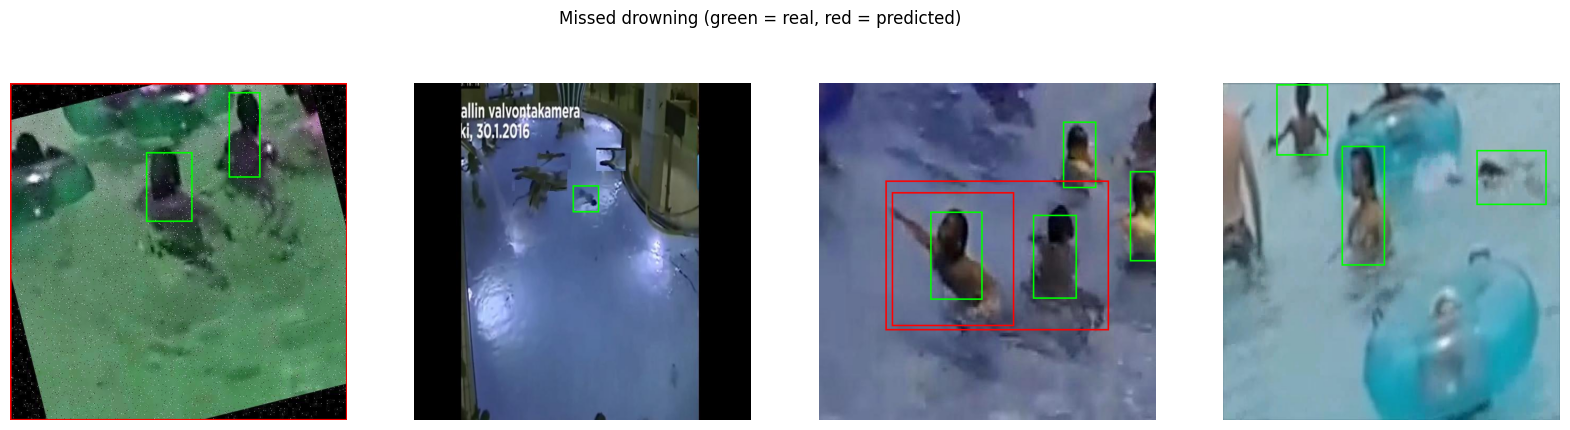

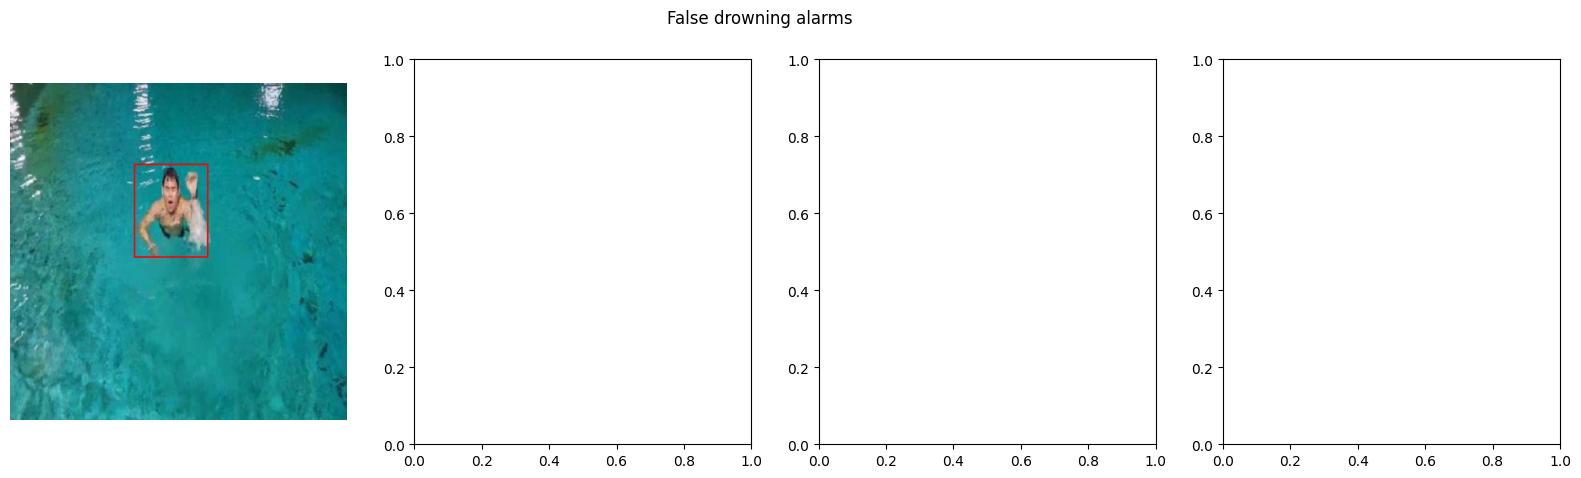

In [4]:
import random, matplotlib.pyplot as plt
from PIL import Image, ImageDraw
best = YOLO(f'{RUNS}/yolo11n_videosplit/weights/best.pt')
test = pathlib.Path('/content/sdd_clean/split_test.txt').read_text().splitlines()
random.seed(1)
missed, false_alarm = [], []
for p in random.sample(test, 300):
    lbl = pathlib.Path(p.replace('/images/', '/labels/')).with_suffix('.txt')
    gt = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
    n_gt = sum(1 for g in gt if g[0] == '0')            # real drowning boxes
    r = best.predict(p, conf=0.25, verbose=False)[0]
    n_pred = int((r.boxes.cls == 0).sum())              # predicted drowning boxes
    if n_gt > n_pred:               missed.append((p, gt, r))
    elif n_pred > 0 and n_gt == 0:  false_alarm.append((p, gt, r))
print(len(missed), 'images with missed drowning,', len(false_alarm), 'with false drowning alarms (out of 300)')

def show(items, title, fname):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5)); fig.suptitle(title)
    for ax, (p, gt, r) in zip(axes, items[:4]):
        im = Image.open(p).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
        for g in gt:                                     # green = real drowning
            c, x, y, w, h = map(float, g[:5])
            if int(c) == 0:
                d.rectangle([(x-w/2)*W, (y-h/2)*H, (x+w/2)*W, (y+h/2)*H], outline='lime', width=3)
        for b, c in zip(r.boxes.xyxy.tolist(), r.boxes.cls.int().tolist()):
            if c == 0: d.rectangle(b, outline='red', width=3)   # red = model says drowning
        ax.imshow(im); ax.axis('off')
    plt.savefig(f'{RUNS}/{fname}.png', bbox_inches='tight'); plt.show()

show(missed, 'Missed drowning (green = real, red = predicted)', 'failures_missed')
show(false_alarm, 'False drowning alarms', 'failures_false_alarm')